# Taller B1-T1 · Quantfolio

**Toolkit de extracción multifuente, análisis bursátil y gestión de carteras con simulación de Monte Carlo.**

Este cuaderno es el punto de entrada reproducible del taller: recorre la ingesta de datos (acciones, ETF de
índices, bonos, criptomonedas y macroeconomía), el modelado de series y carteras, los informes y la simulación
Monte Carlo. La cartera de referencia mezcla las cuatro clases de activo; cada clase tiene además su propio
cuaderno dedicado en `notebooks/portfolio_*.ipynb`.

Requisitos: haber ejecutado `uv sync` y disponer de conexión a internet (la suite de pruebas no la necesita).

In [1]:
"""Cuaderno de demostración: recorrido reproducible del toolkit Quantfolio."""

import warnings

import pandas as pd

from quantfolio import (
    CachedPriceSource,
    FredMacroSource,
    MonteCarloParameters,
    Portfolio,
    create_price_source_registry,
)

sources = create_price_source_registry()

#: yfinance todavía usa argumentos ``inplace`` que pandas 3 marca como obsoletos.
warnings.filterwarnings("ignore", message=".*inplace keyword.*")

START = "2025-01-02"
END = pd.Timestamp.now().normalize()

STOCKS = ["AAPL", "JPM", "XOM"]
INDEX_ETFS = ["SPY", "EFA", "EEM"]
BONDS = ["SHY", "IEF", "HYG"]
BTC = "BTC/USD"
ETH = "ETH/USD"
CRYPTO = [BTC, ETH]

#: Cartera diversificada: 60 % renta variable, 30 % renta fija y 10 % cripto.
WEIGHTS = {
    "AAPL": 0.10,
    "JPM": 0.10,
    "XOM": 0.10,
    "SPY": 0.10,
    "EFA": 0.10,
    "EEM": 0.10,
    "SHY": 0.10,
    "IEF": 0.10,
    "HYG": 0.10,
    BTC: 0.05,
    ETH: 0.05,
}

SP500 = "^GSPC"
IBEX = "^IBEX"
INDEXES = [SP500, IBEX]
CACHE_SAMPLE = STOCKS[0]
PERIODS_PER_YEAR = 252

/var/folders/93/6yzgxmgj67l2gq0bjd_qf33c0000gn/T/ipykernel_35713/77094630.py:15: RuntimeWarning: ALPHA_VANTAGE_API_KEY no está configurada; se continúa sin Alpha Vantage.
  sources = create_price_source_registry()


## 1 · Extracción multifuente: acciones e índices de referencia (Yahoo Finance)

`get_many()` descarga varias series en lote a partir de una lista de activos. Cada serie se normaliza en un
objeto `PriceSeries` con su ticker, su origen, sus estadísticos automáticos y sus precios limpios.

Las tres acciones alimentan la cartera diversificada. Los índices `^GSPC` e `^IBEX` se descargan como **series
de referencia**: no son invertibles directamente, así que la cartera usa ETF que los replican (se descargan en
la sección 5).

In [2]:
yahoo = sources["yahoo"]

stocks = yahoo.get_many(STOCKS, start=START)
indices = yahoo.get_many(INDEXES, start=START)

for ticker, asset in {**stocks, **indices}.items():
    print(
        f"{ticker:>8} | {asset.source:<13} | "
        f"{asset.prices.index.min().date()} → {asset.prices.index.max().date()} | "
        f"{len(asset.prices)} observaciones"
    )

    AAPL | Yahoo Finance | 2025-01-02 → 2026-11-05 | 463 observaciones
     JPM | Yahoo Finance | 2025-01-02 → 2026-11-05 | 463 observaciones
     XOM | Yahoo Finance | 2025-01-02 → 2026-11-05 | 463 observaciones
   ^GSPC | Yahoo Finance | 2025-01-02 → 2026-11-05 | 463 observaciones
   ^IBEX | Yahoo Finance | 2025-01-02 → 2026-11-06 | 473 observaciones


## 2 · Una segunda API: Kraken

Kraken expone una API pública OHLC sin clave. Su adaptador devuelve **exactamente el mismo objeto interno** que
Yahoo Finance: la capa de análisis es independiente de la API consultada. La cartera usa dos pares (`BTC/USD` y
`ETH/USD`) y el cuaderno dedicado de cripto amplía el universo a cuatro.

Kraken solo conserva las últimas 720 velas diarias (≈2 años) y la vela de hoy todavía se está formando, así que
`END` la excluye para que dos ejecuciones del mismo día coincidan. Si `START` deja de estar cubierto, adelántalo a
una fecha dentro de los últimos ~700 días y mantén la misma fecha en los demás cuadernos.

In [3]:
kraken = sources["kraken"]
crypto = kraken.get_many(CRYPTO, start=START, end=END)

btc = crypto[BTC]
print(f"{type(btc).__name__}: {btc.ticker} | {btc.source} | {len(btc.prices)} observaciones")
print(f"Media: {btc.mean_price:,.0f} USD | Desviación típica: {btc.std_price:,.0f} USD")
print(f"¿Mismo objeto interno que las acciones? {type(btc) is type(stocks['AAPL'])}")

PriceSeries: BTC/USD | Kraken | 673 observaciones
Media: 88,992 USD | Desviación típica: 17,349 USD
¿Mismo objeto interno que las acciones? True


## 3 · Alpha Vantage opcional

Con `ALPHA_VANTAGE_API_KEY` configurada, el registro valida la clave y expone este proveedor de forma explícita.
Sin clave, el cuaderno continúa con Yahoo y Kraken y avisa de que Alpha Vantage no está disponible.

In [4]:
from datetime import UTC, datetime, timedelta

if "alpha-vantage" in sources:
    alpha_vantage = sources["alpha-vantage"]
    print(f"Plan: {alpha_vantage.plan.value} | índices: {alpha_vantage.indexes_enabled}")
    recent_start = (datetime.now(UTC).date() - timedelta(days=60)).isoformat()
    ibm = alpha_vantage.get_prices("IBM", start=recent_start)
    print(f"{ibm.ticker}: {len(ibm.prices)} observaciones | {ibm.source}")
else:
    print("Alpha Vantage no está disponible; el cuaderno continúa sin este proveedor.")

Alpha Vantage no está disponible; el cuaderno continúa sin este proveedor.


## 4 · Tipología adicional: tipos de interés (FRED)

`FredMacroSource` descarga indicadores macroeconómicos a través de **ALFRED**, el archivo de *vintages* de
FRED, sin clave de API, y los normaliza en `MacroSeries`. Cada serie registra su `vintage_date`, la fecha
del archivo consultado, y el parámetro `as_of` recupera los valores que se conocían en una fecha pasada,
sin *look-ahead* de revisiones. Aquí se usa el rendimiento del bono estadounidense a 10 años (`DGS10`).

In [2]:
fred = FredMacroSource()
rates = fred.get_series("DGS10", start=START)
pinned = fred.get_series("DGS10", start=START, as_of="2025-03-14")

print(f"{type(rates).__name__}: {rates.series_id} | {rates.source}")
# MacroSeries.values es un campo del modelo, no el .values de pandas.
recent_rates = vars(rates)["values"].tail(3).round(2).to_list()
print(f"Últimos valores (%): {recent_rates}")
print(f"Vintage de la descarga: {rates.vintage_date:%Y-%m-%d}")
pinned_rates = vars(pinned)["values"].tail(3).round(2).to_list()
print(f"Valores publicados al 2025-03-14 (%): {pinned_rates}")

MacroSeries: DGS10 | FRED
Últimos valores (%): [4.91, 4.95, 4.9]
Vintage de la descarga: 2026-11-06
Valores publicados al 2025-03-14 (%): [4.28, 4.32, 4.27]


## 5 · Caché CSV local

`CachedPriceSource` envuelve a cualquier proveedor y guarda cada serie en `data/<proveedor>/<ticker>.csv`. El
archivo se reutiliza mientras cubra el intervalo solicitado y su último dato siga vigente; si no, se descarga y
se reemplaza.

In [6]:
cached = CachedPriceSource(sources["yahoo"], cache_dir="data")

first = cached.get_prices(CACHE_SAMPLE, start=START)
second = cached.get_prices(CACHE_SAMPLE, start=START)

print("Origen de la primera llamada:", first.source)
print("Origen de la segunda llamada:", second.source)

Origen de la primera llamada: Yahoo Finance
Origen de la segunda llamada: Yahoo Finance (cache)


## 6 · La cartera diversificada

La cartera de referencia combina las cuatro clases con una estructura 60/30/10: 60 % de renta variable (mitad
acciones individuales, mitad ETF de índices), 30 % de renta fija y 10 % de cripto como satélite.

| Bloque | Peso | Activos |
|---|---:|---|
| Acciones | 30 % | AAPL, JPM, XOM |
| ETF de índices | 30 % | SPY, EFA, EEM |
| Renta fija | 30 % | SHY, IEF, HYG |
| Cripto | 10 % | BTC/USD, ETH/USD |

`Portfolio` valida las ponderaciones (finitas, no negativas, con clave para cada activo) y las **normaliza**
para que sumen 1; después alinea los calendarios bursátiles por intersección y calcula las métricas ponderadas.
La cobertura será inferior al 100 % porque la cripto cotiza los fines de semana y los activos de Yahoo no: la
intersección conserva solo los días hábiles comunes.

In [7]:
portfolio = Portfolio(
    assets={
        **cached.get_many(STOCKS + INDEX_ETFS + BONDS, start=START),
        **crypto,
    },
    weights=WEIGHTS,
)

print("Pesos normalizados:")
for ticker, weight in portfolio.weights.items():
    print(f"  {ticker}: {weight:.2%}")

print("\nDiagnóstico de alineación temporal:", portfolio.alignment_summary())

print("\nEstadísticos anualizados:")
for name, value in portfolio.summary(periods_per_year=PERIODS_PER_YEAR).items():
    print(f"  {name}: {value:.6f}")

Pesos normalizados:
  AAPL: 10.00%
  JPM: 10.00%
  XOM: 10.00%
  SPY: 10.00%
  EFA: 10.00%
  EEM: 10.00%
  SHY: 10.00%
  IEF: 10.00%
  HYG: 10.00%
  BTC/USD: 5.00%
  ETH/USD: 5.00%

Diagnóstico de alineación temporal: {'union_dates': 673, 'common_dates': 463, 'coverage': 0.687964338781575}

Estadísticos anualizados:
  mean_daily_return: 0.000568
  daily_volatility: 0.008084
  annualized_return_approx: 0.143088
  annualized_volatility: 0.128322


In [8]:
sleeves = {
    "Acciones": STOCKS,
    "ETF de índices": INDEX_ETFS,
    "Renta fija": BONDS,
    "Cripto": CRYPTO,
}

for name, tickers in sleeves.items():
    sleeve_weight = sum(portfolio.weights[ticker] for ticker in tickers)
    print(f"{name:<15} {sleeve_weight:.2%}")

Acciones        30.00%
ETF de índices  30.00%
Renta fija      30.00%
Cripto          10.00%


La cobertura ronda el 69 %: la unión incluye los fines de semana de la cripto y la intersección conserva
solo los días hábiles comunes. El informe lo advierte y las métricas se calculan solo con esas fechas. Es el
precio de mezclar un calendario de siete días con uno de lunes a viernes; el cuaderno dedicado de cripto evita
esa pérdida al analizar la clase por separado.

## 7 · Informe Markdown parametrizable

`report()` genera composición, métricas, calidad de los datos y advertencias de riesgo derivadas del estado real
de la cartera (cobertura de alineación, concentración y longitud de la muestra).

In [9]:
from IPython.display import Markdown

Markdown(portfolio.report())

# Informe de la cartera

## 1. Composición

| Activo | Peso |
|---|---:|
| AAPL | 10.00% |
| JPM | 10.00% |
| XOM | 10.00% |
| SPY | 10.00% |
| EFA | 10.00% |
| EEM | 10.00% |
| SHY | 10.00% |
| IEF | 10.00% |
| HYG | 10.00% |
| BTC/USD | 5.00% |
| ETH/USD | 5.00% |

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 0.0568% |
| Volatilidad diaria | 0.8084% |
| Rentabilidad anualizada aproximada | 14.31% |
| Volatilidad anualizada | 12.83% |

## 3. Calidad de los datos

- Activos: 11
- Fechas en la unión de calendarios: 673
- Fechas comunes a todos los activos: 463
- Cobertura tras la alineación: 68.8%
- Observaciones de rentabilidad: 462

## 4. Advertencias de riesgo

- Las rentabilidades históricas no garantizan resultados futuros.
- La simulación de Monte Carlo depende de los supuestos de rentabilidad y volatilidad.
- La alineación temporal descarta el 31.2% de las fechas; las métricas solo usan días hábiles comunes a todos los activos.

In [10]:
# El informe es parametrizable: se pueden omitir secciones o cambiar la anualización.
print(portfolio.report(include_warnings=False))

# Informe de la cartera

## 1. Composición

| Activo | Peso |
|---|---:|
| AAPL | 10.00% |
| JPM | 10.00% |
| XOM | 10.00% |
| SPY | 10.00% |
| EFA | 10.00% |
| EEM | 10.00% |
| SHY | 10.00% |
| IEF | 10.00% |
| HYG | 10.00% |
| BTC/USD | 5.00% |
| ETH/USD | 5.00% |

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 0.0568% |
| Volatilidad diaria | 0.8084% |
| Rentabilidad anualizada aproximada | 14.31% |
| Volatilidad anualizada | 12.83% |

## 3. Calidad de los datos

- Activos: 11
- Fechas en la unión de calendarios: 673
- Fechas comunes a todos los activos: 463
- Cobertura tras la alineación: 68.8%
- Observaciones de rentabilidad: 462


## 8 · Panel analítico de visualizaciones

`plots_report()` muestra la evolución de precios **reajustada a base 100**, la rentabilidad acumulada por
activo, la matriz de correlación y la evolución del valor de la cartera (base 100).

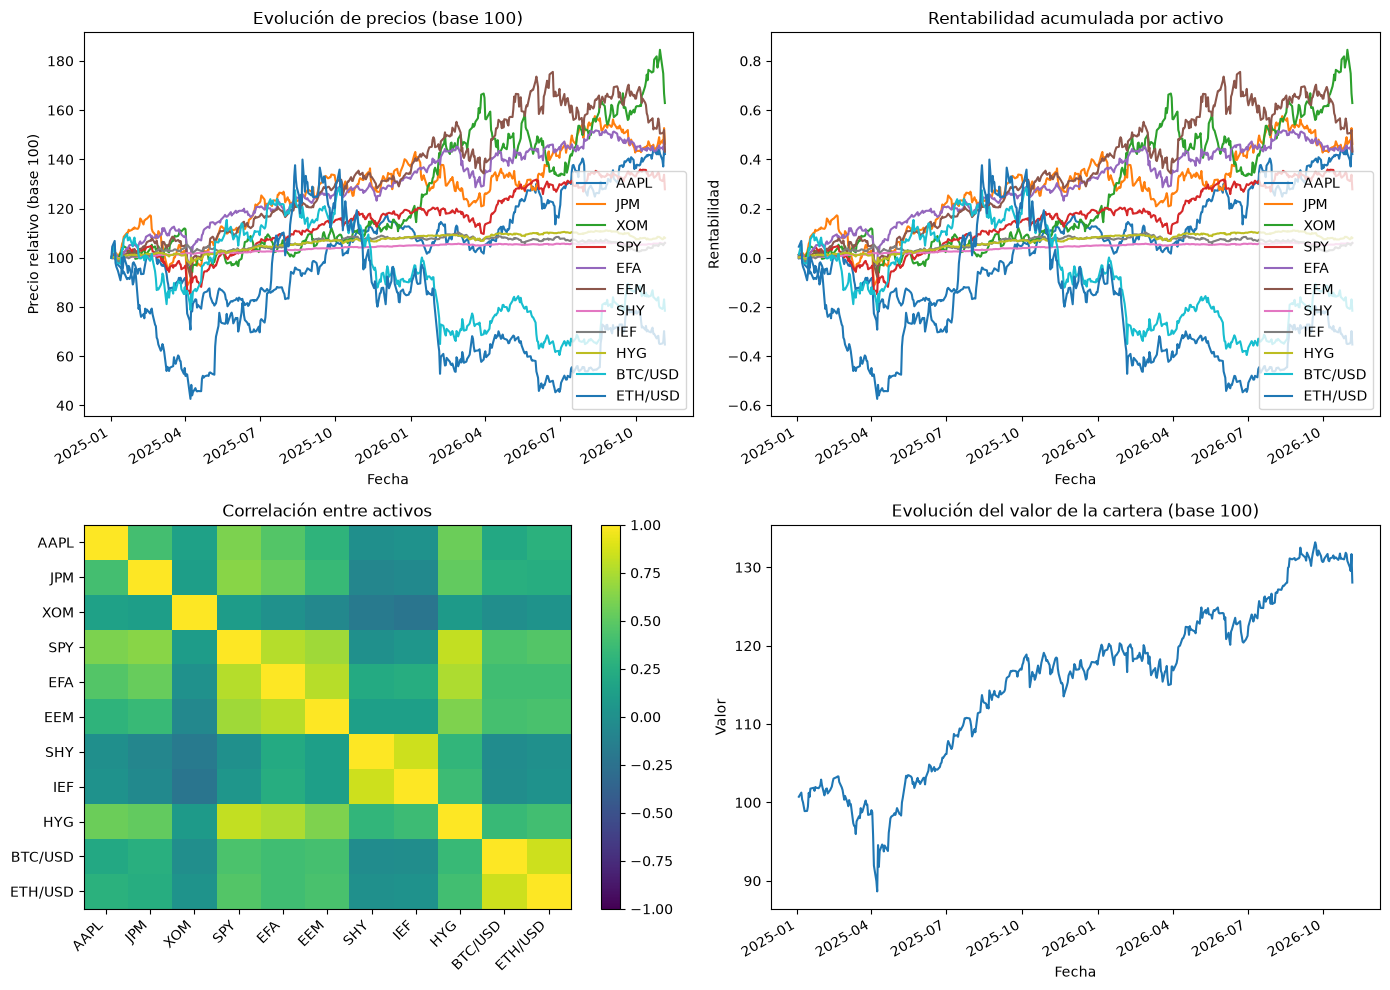

In [11]:
portfolio.plots_report()

## 9 · Monte Carlo de la cartera

La simulación modela la cartera con un movimiento browniano geométrico parametrizable (`MonteCarloParameters`):
número de trayectorias, horizonte, valor inicial, supuestos de rentabilidad y volatilidad, semilla y número de
periodos por año. La cartera principal usa 252 periodos porque la intersección con los activos de Yahoo la
convierte en una serie de días hábiles; el cuaderno de cripto usa 365.

In [12]:
simulations = portfolio.simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=2_000,
        horizon=PERIODS_PER_YEAR,
        periods_per_year=PERIODS_PER_YEAR,
        seed=42,
    )
)

final_values = simulations.iloc[-1]
print(f"Valor inicial: {simulations.iloc[0, 0]:,.0f}")
print(final_values.describe(percentiles=[0.05, 0.5, 0.95]).round(2))

Valor inicial: 10,000
count     2000.00
mean     11533.70
std       1513.77
min       7676.07
5%        9243.24
50%      11391.93
95%      14363.25
max      17078.10
Name: 252, dtype: float64


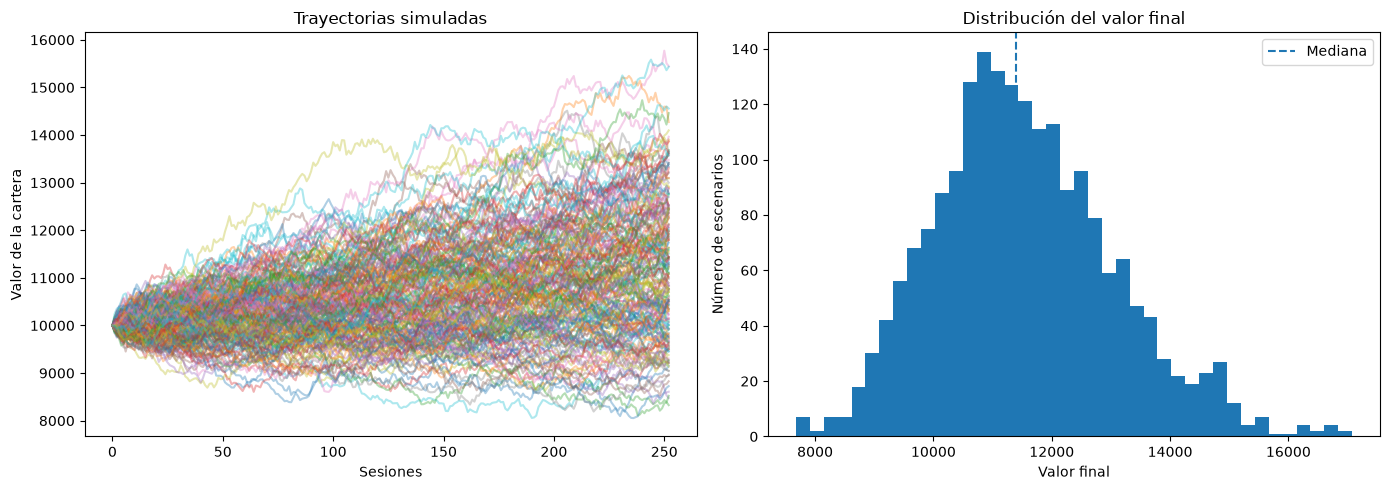

In [13]:
portfolio.plot_simulation(simulations, max_paths=200)

## 10 · Monte Carlo de un activo con supuestos propios

La misma simulación está disponible en `PriceSeries`. Aquí se simula el S&P 500 asumiendo un 8 % de rentabilidad
anual y un 18 % de volatilidad, en lugar de los valores históricos, y partiendo del último cierre observado. El
`^GSPC` es una serie de referencia: no forma parte de la cartera.

In [14]:
scenario = indices[SP500].simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=1_000,
        horizon=252,
        return_assumption=0.08,
        volatility_assumption=0.18,
        seed=7,
    )
)

print(f"Punto de partida: {scenario.iloc[0, 0]:,.0f} (último cierre de {SP500})")
print(f"Mediana a un año: {scenario.iloc[-1].median():,.0f}")

Punto de partida: 7,354 (último cierre de ^GSPC)
Mediana a un año: 7,963


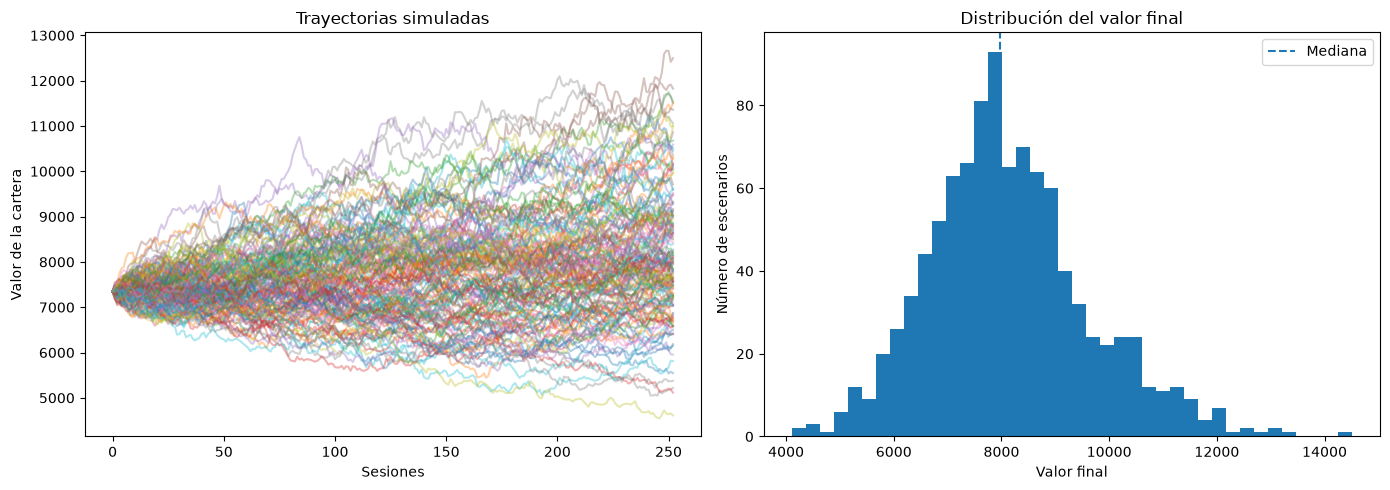

In [15]:
indices[SP500].plot_simulation(scenario, max_paths=150)

## 11 · Carteras por clase de activo

La cartera diversificada es la vista de conjunto. Cada clase tiene su propio cuaderno para estudiar su
comportamiento aislado, con el mismo pipeline de ingesta, informe, gráficos y Monte Carlo:

- [`portfolio_stocks.ipynb`](portfolio_stocks.ipynb) — cinco acciones de sectores distintos.
- [`portfolio_indices.ipynb`](portfolio_indices.ipynb) — cinco ETF de índices.
- [`portfolio_fixed_income.ipynb`](portfolio_fixed_income.ipynb) — cinco ETF de bonos.
- [`portfolio_crypto.ipynb`](portfolio_crypto.ipynb) — cuatro pares de Kraken con calendario de 365 días.

## 12 · Calidad del código y siguientes pasos

Los controles de calidad del proyecto se ejecutan con:

```console
uv run ruff check .
uv run ruff format --check .
uv run mypy src tests
uv run pytest
```

- La biblioteca vive en `src/quantfolio/` (solo código importable y probado); este cuaderno y la caché `data/`
  no forman parte del paquete.
- Análisis estático con SonarQube (perfiles estrictos `Python Strict`/`IPython Strict` y *quality gate*
  `Quantfolio Strict`, sin ninguna incidencia): los pasos están documentados en el README.
- Diagrama de arquitectura UML y de flujo: [`docs/architecture.md`](../docs/architecture.md).
- Correspondencia completa con el enunciado del taller: README del repositorio.